# סיווג משלחי יד | מבחן מדען נתונים — הלשכה המרכזית לסטטיסטיקה

**הגשה:** מחברת Python עצמאית שמורידה את קובץ ה-Excel המקורי מ-GitHub, בוחנת במפורש כל אחד מ-18 השדות מול גיליון `Metadata`, מאמנת מסווג, ומציגה תחזיות ותכנית הטמעה.

**ההבחנה המרכזית:** הנתונים **סינתטיים**. לפי מסמך המטלה כ-90% מהסימולים הידניים נכונים במדגם של התהליך, אך אין בחוברת תוויות אמת בלתי תלויות לבדיקת הטענה. לכן כל מדד כאן הוא התאמה לתוויות סימולציה, **לא** אומדן דיוק תפעולי.

**הבהרה:** הקוד אינו מייצר ערכים אפשריים, קטגוריות מקצוע או רשומות סקר. הוא משתמש בתוכן המקור ובתיעוד הקיים. כל החלטת עיבוד נעשית בנפרד ומנומקת, ואינה מוצגת כאילו נכתבה על ידי עורכי ה-Metadata.

**מקור:** [DUMMY_DATASET.xlsx ב-GitHub](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx) | [קוד מחברת ב-GitHub](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey_occupation_classification.ipynb) | [הרצה ב-Colab](https://colab.research.google.com/github/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey_occupation_classification.ipynb)

**הנחות עבודה גלויות:** זמינות סמל ענף סופי בזמן החיזוי אינה מאומתת; אין מזהה משתתף המקשר בין שידורים; אין עותק של קידוד אמת שנקבע בהכרעת מומחים. המגבלות האלה מטופלות כהגבלות על המסקנות, ולא כמקומות להמצאת מידע.

## 1. סביבת עבודה

הקוד משתמש בחבילות הרגילות של Colab. לא נדרש SSH, אסימון גישה, הרשאות Drive או העלאה ידנית. תהליך הטעינה מוגדר פעם אחת בלבד.

In [1]:
from __future__ import annotations
import hashlib
import io
import re
import sys
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 48)
pd.set_option("display.max_rows", 20)
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__)

Python: 3.13.5 | pandas: 2.2.3 | scikit-learn: 1.8.0


## 2. טעינה ישירה של שתי לשוניות Excel

קובץ המקור נמצא כבר ב-GitHub. נשמרת בדיקת SHA-256 של קובץ המקור, כדי שלא יוצגו מדדים ממסד נתונים שונה בטעות. אם המקור ישתנה, המחברת תדווח על כך במקום להשוות תוצאות שגויות. מתוך `Survey Dataset` מוסרת רק שורת סיכום ללא `ID`, שאינה רשומת משתתף. גיליון `Metadata` נלקח כפי שהוא, מארבע העמודות המאוכלסות, ללא שחזור ידני של ההגדרות.

In [2]:
SOURCE_URL = (
    "https://raw.githubusercontent.com/shulruferor-sudo/Advance-Data-Science/"
    "main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx"
)
EXPECTED_SOURCE_SHA256 = "e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac"

request = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "cbs-survey-notebook"})
with urllib.request.urlopen(request, timeout=40) as response:
    workbook_bytes = response.read()
actual_sha256 = hashlib.sha256(workbook_bytes).hexdigest()
if actual_sha256 != EXPECTED_SOURCE_SHA256:
    raise ValueError("GitHub workbook changed: review the new source before interpreting results")

workbook = pd.ExcelFile(io.BytesIO(workbook_bytes), engine="openpyxl")
if set(workbook.sheet_names) != {"Survey Dataset", "Metadata"}:
    raise ValueError(f"Unexpected Excel sheets: {workbook.sheet_names}")

survey_sheet = pd.read_excel(
    workbook, sheet_name="Survey Dataset",
    dtype={"SemelAnafSofi": "string", "SemelMishlachSofi": "string"}
)
metadata = pd.read_excel(workbook, sheet_name="Metadata", usecols="A:D", dtype="string")
metadata.columns = metadata.columns.astype(str).str.strip()
metadata = metadata.dropna(subset=["משתנה"]).copy()
metadata["משתנה"] = metadata["משתנה"].str.strip()

# Keep the original worksheet unchanged. This row has no participant ID.
non_participant_rows = survey_sheet.loc[survey_sheet["ID"].isna()].copy()
survey = survey_sheet.loc[survey_sheet["ID"].notna()].copy()
survey["ID"] = pd.to_numeric(survey["ID"], errors="raise").astype("int64")
for column in ("SemelAnafSofi", "SemelMishlachSofi"):
    survey[column] = survey[column].astype("string").str.strip()
survey = survey.reset_index(drop=True)

assert survey.shape == (200, 18)
assert metadata.shape == (18, 4)
assert survey["ID"].is_unique
assert metadata["משתנה"].is_unique
assert set(survey.columns) == set(metadata["משתנה"])
assert len(non_participant_rows) == 1

print("Source SHA-256:", actual_sha256)
print("Participants:", len(survey), "| Fields:", survey.shape[1],
      "| Metadata definitions:", len(metadata),
      "| Excluded non-participant rows:", len(non_participant_rows))
display(survey[["ID", "EzoAvoda", "SemelMishlachSofi"]].head(5))

Source SHA-256: e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac
Participants: 200 | Fields: 18 | Metadata definitions: 18 | Excluded non-participant rows: 1


,ID,EzoAvoda,SemelMishlachSofi
0,1,סגן מנהל אגף,2120
1,2,טכנאית רדיותרפיה,3311
2,3,נותנת תמיכה ללקוחות שמבקשים עזרה,3512
3,4,שומר בבית הספר,5414
4,5,מטפל בקשיש,5322


## 3. בדיקת המבנה ומקור המשמעות של כל עמודה

הנתונים מוגדרים כטקסט, מספר או תאריך בהתאם ל-`Metadata` המקורי. קודים של ענף ומקצוע נשמרים כמחרוזות; אפסים מובילים, אם יימצאו, לא יימחקו. ערכי קוד אפשריים נבדקים **רק אם המקור אכן מפרט אותם**. אין השלמת קטגוריות חסרות מתוך השערה.

הטבלה הקומפקטית להלן מציגה ארבעה שדות בכל פעם כדי למנוע טבלה רחבה שאינה קריאה ב-Colab בנייד.

In [3]:
expected_columns = metadata["משתנה"].tolist()
assert set(survey.columns) == set(expected_columns), "Field names differ from original Metadata"
if survey.columns.tolist() != expected_columns:
    print("Source note: metadata and survey sheet column order differs; all fields are reconciled by name.")

for start in range(0, len(metadata), 4):
    print(f"Metadata fields {start+1}–{min(start+4, len(metadata))}")
    display(metadata.iloc[start:start+4][["משתנה", "הסבר", "פורמט"]].reset_index(drop=True))

# Parse only the codes explicitly enumerated in the workbook's Metadata sheet.
code_domains = {}
for _, row in metadata.iterrows():
    raw = row["ערכים אפשריים"]
    if pd.notna(raw):
        matched = re.findall(r"(?m)^\s*(\d+)\s*[.]", str(raw))
        if matched:
            code_domains[str(row["משתנה"])] = {int(x) for x in matched}

print("Fields with explicitly enumerated codes in Metadata:", list(code_domains))
for column, allowed in code_domains.items():
    actual = pd.to_numeric(survey[column], errors="coerce")
    observed = set(actual.dropna().astype(int))
    print(column, "| defined codes:", sorted(allowed),
          "| observed codes:", sorted(observed),
          "| out-of-domain:", sorted(observed - allowed))
    assert not (observed - allowed), f"Unexpected code in {column}"

Source note: metadata and survey sheet column order differs; all fields are reconciled by name.
Metadata fields 1–4


,משתנה,הסבר,פורמט
0,ID,מספר רץ,INTEGER
1,YeshuvAvoda,שם יישוב עבודה,TEXT
2,ShemAvoda,שם מקום העבודה שלך,TEXT
3,SugAvoda,הפעילות העיקרית של מקום העבודה,TEXT


Metadata fields 5–8


,משתנה,הסבר,פורמט
0,ShemMachlaka,אגף או מחלקה שהנסקר עובד,TEXT
1,SugMachlaka,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד,TEXT
2,EzoAvoda,עבודה שהנסקר עושה במקום עבודה זה,TEXT
3,TeurPeula,הפעולות העיקריות שהנסקר עושה במקום עבודה,TEXT


Metadata fields 9–12


,משתנה,הסבר,פורמט
0,TeurTafkid,מהו תואר המשרה של הנסקר במקום עבודה זה (במי...,TEXT
1,MenahelEtMi,האם הנסקר מנהל או ממונה על עובדים אחרים?,INTEGER
2,MaamadAvoda,מעמד הנסקר במקום עבודה זה,INTEGER
3,MakorSachar,מקור השכר של הנסקר (השדה מלא רק במידה והנסקר...,INTEGER


Metadata fields 13–16


,משתנה,הסבר,פורמט
0,TeudaGvoha,התעודה או התואר הגבוה ביותר של הנסקר,INTEGER
1,shnotlimud,שנות הלימוד של הנסקר,INTEGER
2,Gil,גיל הנסקר,INTEGER
3,SemelAnafSofi,סמל ענף כלכלי של מקום העבודה - מורכב מ-4 ספר...,TEXT


Metadata fields 17–18


,משתנה,הסבר,פורמט
0,TarichHathala,תאריך התחלת התפקיד,DATE
1,SemelMishlachSofi,סמל משלח יד - מורכב מ-4 ספרות לפי תקן בינלאומי,TEXT


Fields with explicitly enumerated codes in Metadata: ['MenahelEtMi', 'MaamadAvoda', 'MakorSachar', 'TeudaGvoha']
MenahelEtMi | defined codes: [1, 2, 3] | observed codes: [1, 2, 3] | out-of-domain: []
MaamadAvoda | defined codes: [1, 2, 3, 4, 5, 6, 7] | observed codes: [1, 2, 4, 6] | out-of-domain: []
MakorSachar | defined codes: [1, 2, 3, 4] | observed codes: [1, 2, 3, 4] | out-of-domain: []
TeudaGvoha | defined codes: [1, 2, 3, 4, 5, 6, 7, 8, 9] | observed codes: [1, 2, 3, 4, 5, 6, 7] | out-of-domain: []


## 4. פרופיל מלא של כל השדות, ללא עיבוד מקדים סמוי

לכל שדה מחושבים סוג הנתונים המקורי, מספר החסרים, שכיחויות, מספר ערכים שונים ודוגמאות. חסרים שנשמרו כ-NaN אינם מוחלפים בשלב האבחון. מחרוזות `כנ"ל`, `חסוי`, `0` ודומיהן מדווחות כערכים קיימים ולא כהסבר מומצא. החלפתן לצורך למידה, אם נדרשת, תיעשה רק בעותק מאפיינים ואינה משנה את המקור.

,field,missing,missing_pct,distinct_nonmissing
0,ID,0,0.0,200
1,YeshuvAvoda,0,0.0,21
2,ShemAvoda,0,0.0,82
3,SugAvoda,25,12.5,78
4,ShemMachlaka,64,32.0,61
5,SugMachlaka,134,67.0,35


,field,missing,missing_pct,distinct_nonmissing
6,EzoAvoda,7,3.5,84
7,TeurPeula,136,68.0,32
8,TeurTafkid,172,86.0,16
9,MenahelEtMi,168,84.0,3
10,MaamadAvoda,2,1.0,4
11,MakorSachar,14,7.0,4


,field,missing,missing_pct,distinct_nonmissing
12,TeudaGvoha,2,1.0,7
13,shnotlimud,2,1.0,13
14,Gil,2,1.0,29
15,TarichHathala,0,0.0,42
16,SemelAnafSofi,0,0.0,44
17,SemelMishlachSofi,0,0.0,62


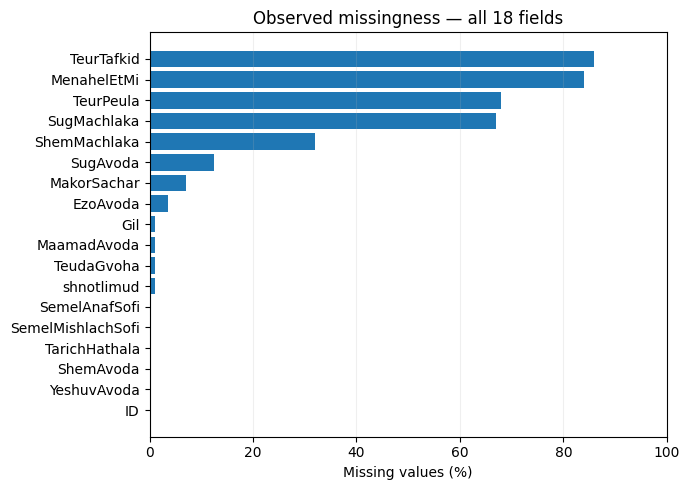

In [4]:
def is_missing(x):
    return pd.isna(x) or (isinstance(x, str) and not x.strip())

profile_rows = []
for column in survey.columns:
    series = survey[column]
    defined = metadata.loc[metadata["משתנה"].eq(column)].iloc[0]
    nonmissing = series.loc[~series.map(is_missing)]
    profile_rows.append({
        "field": column,
        "format_in_metadata": str(defined["פורמט"]).strip(),
        "missing": int(series.map(is_missing).sum()),
        "missing_pct": round(float(series.map(is_missing).mean() * 100), 1),
        "distinct_nonmissing": int(nonmissing.astype("string").str.strip().nunique()),
        "most_frequent": str(nonmissing.astype("string").str.strip().mode().iloc[0]) if len(nonmissing) else "[none]",
    })
field_profile = pd.DataFrame(profile_rows)
assert field_profile.shape[0] == 18
for start in range(0, 18, 6):
    display(field_profile.iloc[start:start+6][["field", "missing", "missing_pct", "distinct_nonmissing"]])

fig, ax = plt.subplots(figsize=(7.0, 5.0))
ordered = field_profile.sort_values("missing_pct")
ax.barh(ordered["field"], ordered["missing_pct"])
ax.set(xlabel="Missing values (%)", title="Observed missingness — all 18 fields", xlim=(0, 100))
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 5. החלטה מפורשת לגבי כל שדה

**מקור ההגדרה** לכל שדה הוא `Metadata` ממש. **ההחלטה אם וכיצד להשתמש בשדה** היא החלטת מידול של המגיש המבוססת על משמעות השדה, זמינות מידע בזמן חיזוי וסיכוני זליגה/שינון. אין כאן טענה שההחלטות הופיעו כ"אפשרויות" בגליון. אין שום תיקון לרשומות המקור.

**כללי טיפול שהוערכו:** מזהים וקודים סופיים אינם מידע גולמי של משתתף; שדות מקצועיים חופשיים נשמרים כערוצי טקסט נפרדים; שדות קוד הם נומינליים ולא מרחק מספרי; שדה מותנה מטופל לפי התנאי המקורי; שדות דמוגרפיים וגיאוגרפיים נסקרים אך לא מוכנסים למודל הראשי ללא הצדקה תפעולית. להלן התייחסות נפרדת לכל אחת מ-18 העמודות.

In [5]:
# These statements are explicit ANALYST decisions, not categories or values
# claimed to exist in the Excel sheet. All source meanings remain in `metadata`.
field_treatments = [
    ("ID", "Identifier / audit", "Integrity and prediction join only; never a feature",
     "Sequential record number, not a cross-submission participant identifier"),
    ("YeshuvAvoda", "Audit; excluded", "Inspect distinct cities and missingness; no model input",
     "Location can be an unstable geographic shortcut, not an occupational activity"),
    ("ShemAvoda", "Grouping; excluded", "Use in exact-description grouping only; do not train on employer names",
     "Employer memorization and disguised record duplication can inflate scores"),
    ("SugAvoda", "Text feature", "Whitespace normalization; independent character TF–IDF channel",
     "Employer activity provides occupational context, not a substitute for duties"),
    ("ShemMachlaka", "Text feature", "Retain department text in separate character TF–IDF channel",
     "Department names are contextual and often missing"),
    ("SugMachlaka", "Text feature", "Retain substantive text; unresolved 'כנ\"ל' treated as missing in model copy",
     "Cannot infer what 'same as above' refers to without an unambiguous source rule"),
    ("EzoAvoda", "Text feature", "Preserve described work; separate character TF–IDF channel",
     "Direct description of what the participant does"),
    ("TeurPeula", "Text feature", "Preserve tasks; unresolved placeholders excluded from model text",
     "Task-level evidence is valuable but sparse"),
    ("TeurTafkid", "Text feature", "Retain job title when meaningful; isolated '0' is flagged and treated as unknown",
     "Optional job-title field; do not mistake '0' for a defined occupation"),
    ("MenahelEtMi", "Nominal feature", "One-hot observed code; preserve unanswered as distinct missing state",
     "Metadata defines management types, not a code for 'does not manage'"),
    ("MaamadAvoda", "Nominal feature", "One-hot employment status; preserve missing explicitly",
     "Status codes have meanings but are not an ordered quantity"),
    ("MakorSachar", "Conditional nominal feature", "One-hot only when status 1 or 5; inconsistent values flagged and masked in model copy",
     "Metadata specifies the salary-source field applies only to employees/cooperative members"),
    ("TeudaGvoha", "Nominal feature", "One-hot qualification code, with missing state; no numeric scaling",
     "Education-category codes are not calibrated distances"),
    ("shnotlimud", "Numeric feature", "Median imputation fitted within training and scaling within pipeline",
     "Count of completed study years; missing is not zero"),
    ("Gil", "Audit; excluded", "Inspect plausible values; no model input in primary proof of concept",
     "Potential demographic shortcut without established necessity"),
    ("SemelAnafSofi", "Leakage-risk audit; excluded", "Preserve as text, check length/X; never use final-coded industry as input",
     "No evidence it would be available before occupation coding"),
    ("TarichHathala", "Audit; excluded", "Parse and inspect dates; do not derive tenure without survey date",
     "Start of position is not the survey-submission timestamp"),
    ("SemelMishlachSofi", "Target", "Train only on fully numeric four-character codes; route X cases to manual review",
     "Hand-coded target may contain label noise; X is explicitly incomplete"),
]
assert len(field_treatments) == 18
assert set(r[0] for r in field_treatments) == set(survey.columns)

treatments = pd.DataFrame(field_treatments, columns=["field", "use", "treatment", "why"])
for column in survey.columns:
    row = treatments.loc[treatments["field"].eq(column)].iloc[0]
    source = metadata.loc[metadata["משתנה"].eq(column)].iloc[0]
    observed = field_profile.loc[field_profile["field"].eq(column)].iloc[0]
    print(f"\n[{column}]  Format: {str(source['פורמט']).strip()} | "
          f"Missing: {observed['missing']}/200 | Distinct: {observed['distinct_nonmissing']}")
    print("Source definition:", " ".join(str(source["הסבר"]).split()))
    print("Model role:", row["use"], "|", row["treatment"])
    print("Reason:", row["why"])


[ID]  Format: INTEGER | Missing: 0/200 | Distinct: 200
Source definition: מספר רץ
Model role: Identifier / audit | Integrity and prediction join only; never a feature
Reason: Sequential record number, not a cross-submission participant identifier

[YeshuvAvoda]  Format: TEXT | Missing: 0/200 | Distinct: 21
Source definition: שם יישוב עבודה
Model role: Audit; excluded | Inspect distinct cities and missingness; no model input
Reason: Location can be an unstable geographic shortcut, not an occupational activity

[ShemAvoda]  Format: TEXT | Missing: 0/200 | Distinct: 82
Source definition: שם מקום העבודה שלך
Model role: Grouping; excluded | Use in exact-description grouping only; do not train on employer names
Reason: Employer memorization and disguised record duplication can inflate scores

[SugAvoda]  Format: TEXT | Missing: 25/200 | Distinct: 78
Source definition: הפעילות העיקרית של מקום העבודה
Model role: Text feature | Whitespace normalization; independent character TF–IDF channel
Rea

## 6. ויזואליזציה עבור כל אחת מ-18 העמודות

כל תרשים נגזר מהערכים הקיימים בלבד. מזהה נבדק כהתפלגות סדר; גיל ושנות לימוד כהיסטוגרמות; תאריך כשנת התחלה; עמודות אחרות בהתפלגות שכיחויות. בעמודות עם טקסט עברי התוויות נשמרות בטבלת שכיחויות קצרה מתחת לתרשים כדי למנוע היפוך תווים במנוע השרטוט. **התרשימים הם EDA, לא טענת איכות חיזוי.**

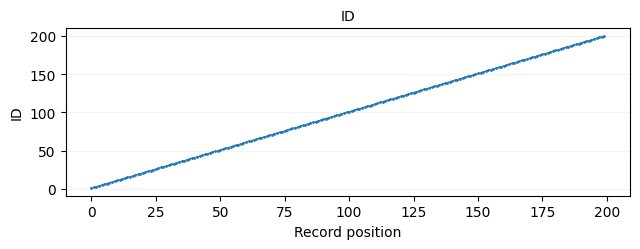

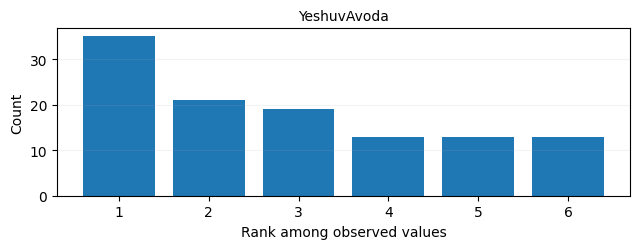

,observed_value,count
rank,,
1,תל אביב,35
2,ירושלים,21
3,חיפה,19
4,רעננה,13
5,הרצליה,13
6,אילת,13


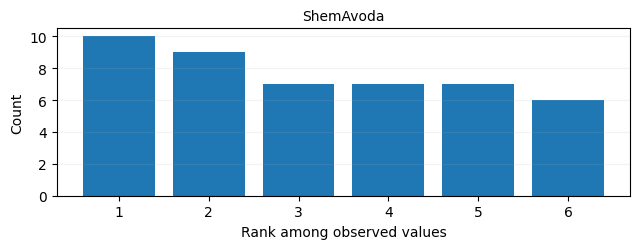

,observed_value,count
rank,,
1,מסעדה,10
2,משרד החינוך,9
3,בנק לאומי,7
4,משטרה,7
5,בית ספר תיכון,7
6,סופר פארם,6


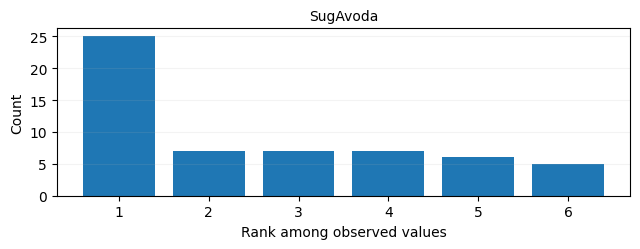

,observed_value,count
rank,,
1,[MISSING],25
2,מסעדה,7
3,בית ספר יסודי,7
4,חנות למכירת בגדים,7
5,אירוח,6
6,מכירת קוסמטיקה,5


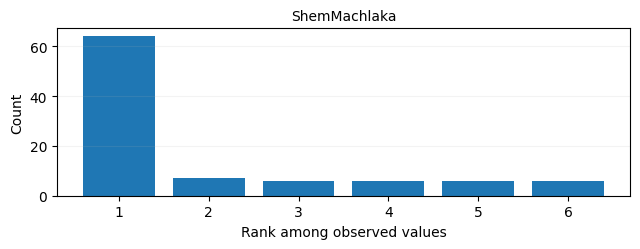

,observed_value,count
rank,,
1,[MISSING],64
2,שמירה,7
3,תמיכה בלקוחות,6
4,קוסמטיקה וטיפוח,6
5,משק,6
6,עובד ניקיון,6


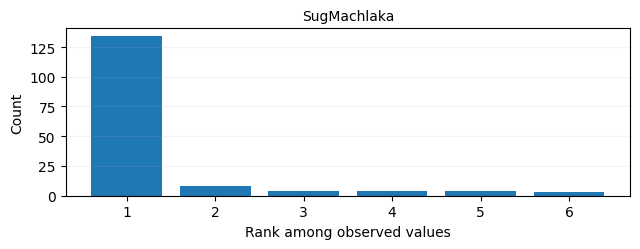

,observed_value,count
rank,,
1,[MISSING],134
2,"כנ""ל",8
3,טיפול בחולי סרטן,4
4,טיפול באנשים עם בעיות,4
5,משחק,4
6,אריזה,3


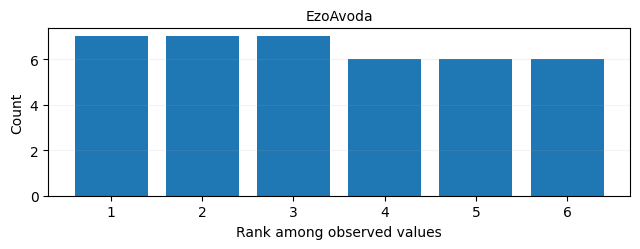

,observed_value,count
rank,,
1,שומר בבית הספר,7
2,[MISSING],7
3,טבח,7
4,קוסמטיקאית,6
5,מנקה בית ספר אחרי הלימודים,6
6,מוכרת,6


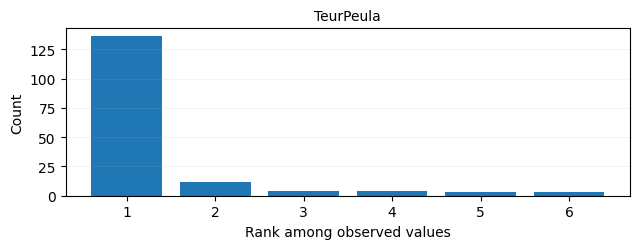

,observed_value,count
rank,,
1,[MISSING],136
2,"כנ""ל",12
3,מפקח על תהליך ייצור צ'יפים,4
4,מסבירה לאנשים לגבי מוצרים של חברת LOREAL,4
5,נותן תמיכה לעובדים בבנק ופוטר בעיות תקשורת,3
6,עוזר לחשמלאי,3


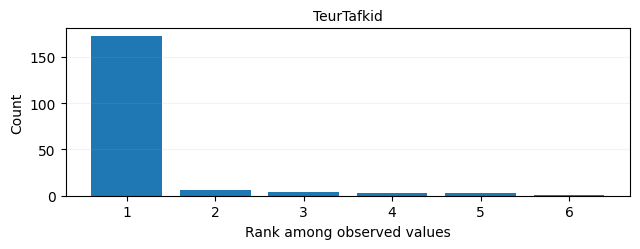

,observed_value,count
rank,,
1,[MISSING],172
2,כלכלן,6
3,"כנ""ל",4
4,סגן מנהל אגף,3
5,טכנאי מחשבים,3
6,0,1


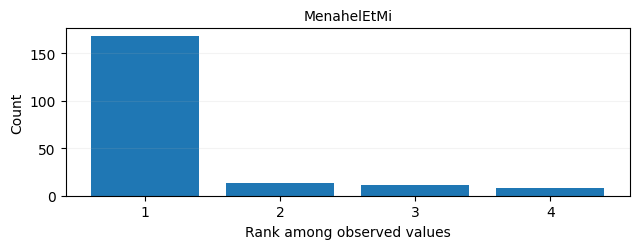

,observed_value,count
rank,,
1,[MISSING],168
2,3.0,13
3,2.0,11
4,1.0,8


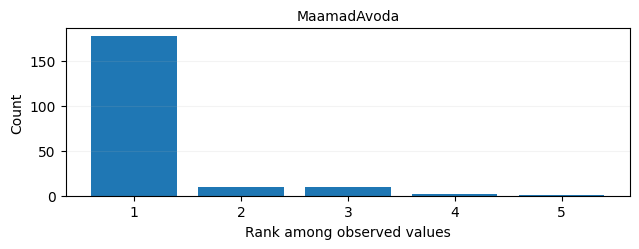

,observed_value,count
rank,,
1,1.0,177
2,4.0,10
3,6.0,10
4,[MISSING],2
5,2.0,1


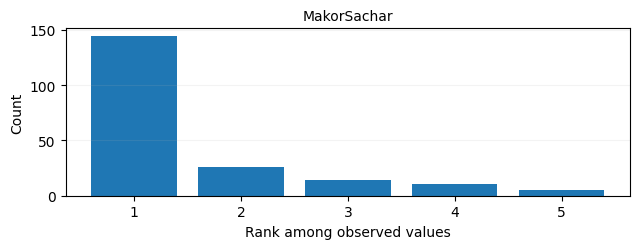

,observed_value,count
rank,,
1,1.0,144
2,2.0,26
3,[MISSING],14
4,3.0,11
5,4.0,5


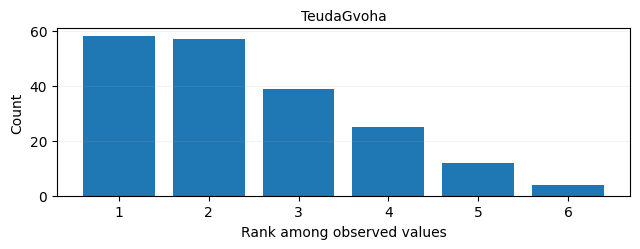

,observed_value,count
rank,,
1,4.0,58
2,3.0,57
3,6.0,39
4,5.0,25
5,2.0,12
6,7.0,4


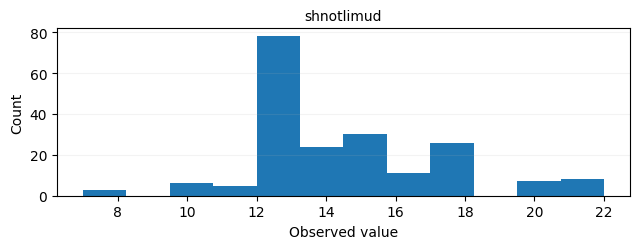

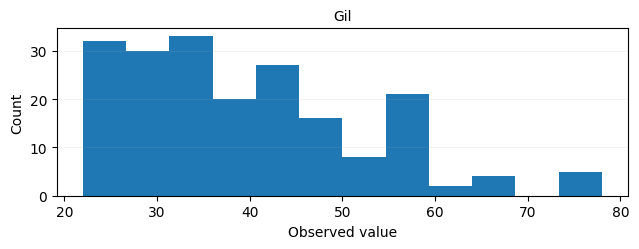

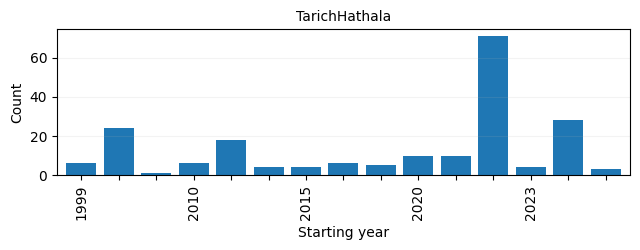

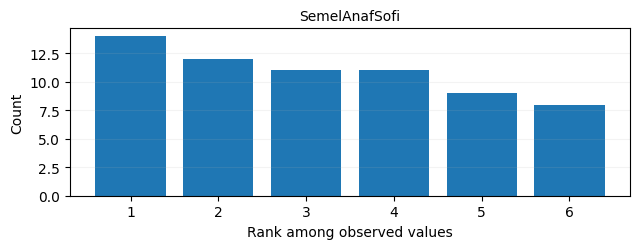

,observed_value,count
rank,,
1,5610,14
2,6201,12
3,8411,11
4,6419,11
5,5510,9
6,4711,8


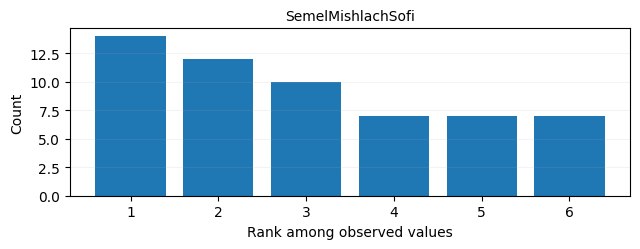

,observed_value,count
rank,,
1,5223,14
2,9112,12
3,2512,10
4,2511,7
5,5414,7
6,5412,7


In [6]:
def plot_observed_field(column: str) -> None:
    s = survey[column]
    fig, ax = plt.subplots(figsize=(6.5, 2.6))
    if column == "ID":
        values = pd.to_numeric(s, errors="coerce")
        ax.plot(np.arange(len(values)), values, marker=".", linewidth=0.7, markersize=2)
        ax.set(xlabel="Record position", ylabel="ID")
    elif column in ("Gil", "shnotlimud"):
        numeric = pd.to_numeric(s, errors="coerce").dropna()
        ax.hist(numeric, bins=min(12, int(numeric.nunique())))
        ax.set(xlabel="Observed value", ylabel="Count")
    elif column == "TarichHathala":
        years = pd.to_datetime(s, errors="coerce").dt.year.dropna().astype(int)
        years.value_counts().sort_index().plot.bar(ax=ax, width=0.8)
        labels = ax.get_xticklabels()
        for k, item in enumerate(labels):
            if k % 3:
                item.set_visible(False)
        ax.set(xlabel="Starting year", ylabel="Count")
    else:
        counts = s.astype("string").str.strip().fillna("[MISSING]").replace("", "[MISSING]").value_counts()
        top = counts.head(6)
        ax.bar(np.arange(1, len(top) + 1), top.values)
        ax.set_xticks(np.arange(1, len(top) + 1))
        ax.set(xlabel="Rank among observed values", ylabel="Count")
    ax.set_title(column, fontsize=10)
    ax.grid(axis="y", alpha=0.14)
    plt.tight_layout()
    plt.show()

    if column not in ("ID", "Gil", "shnotlimud", "TarichHathala"):
        legend = s.astype("string").str.strip().fillna("[MISSING]").replace("", "[MISSING]").value_counts().head(6)
        display(pd.DataFrame({"rank": np.arange(1, len(legend)+1),
                              "observed_value": legend.index.astype(str),
                              "count": legend.values}).set_index("rank"))

for field in survey.columns:
    plot_observed_field(field)

## 7. בקרת תקינות וחריגות יחסי שדות

מפרידים בין **חריגה מתנאי שמוגדר במקור** לבין **בדיקת סבירות שבחר המנתח**. אין תיקון אוטומטי של ענף כלכלי `123` ל-`0123`, אין פענוח `XXXX` למקצוע, ואין השלמת `MenahelEtMi` החסר בערך שאינו מוגדר במטא-דאטה.

מפורשות נבדקים סכמת מספרים/תאריכים, קודי 4 תווים, תוויות `X`, כללי תחולה של מקור השכר, וערכים מילוליים שאינם תיאור מקצועי.

In [7]:
# Numeric and date types: report errors rather than silently coercing malformed data.
for _, source in metadata.iterrows():
    column, fmt = str(source["משתנה"]), str(source["פורמט"]).strip().upper()
    if fmt == "INTEGER":
        numeric = pd.to_numeric(survey[column], errors="coerce")
        malformed = survey[column].notna() & numeric.isna()
        assert malformed.sum() == 0, f"Non-numeric value in {column}"
        not_integral = numeric.notna() & (numeric % 1 != 0)
        assert not bool(not_integral.any()), f"Non-integer numerical entry in {column}"
    elif fmt == "DATE":
        assert pd.to_datetime(survey[column], errors="coerce").notna().all(), column

# A code is 4 numeric characters only when fully coded, not when partially coded.
occupation_code = survey["SemelMishlachSofi"].astype("string")
fully_coded = occupation_code.str.fullmatch(r"[0-9]{4}", na=False)
partially_coded = occupation_code.str.fullmatch(r"[0-9X]{4}", na=False) & occupation_code.str.contains("X", na=False)
assert (fully_coded | partially_coded).all(), "Unclassified target-code format"
assert fully_coded.sum() == 191 and partially_coded.sum() == 9

industry_code = survey["SemelAnafSofi"].astype("string")
industry_complete = industry_code.str.fullmatch(r"[0-9]{4}", na=False)
industry_partial = industry_code.str.fullmatch(r"[0-9X]{4}", na=False) & industry_code.str.contains("X", na=False)
industry_other = ~(industry_complete | industry_partial)

status = pd.to_numeric(survey["MaamadAvoda"], errors="coerce")
salary = pd.to_numeric(survey["MakorSachar"], errors="coerce")
salary_eligible = status.isin([1, 5])  # Derived from the existing Metadata's labelled codes.
salary_rule_conflict = (~salary_eligible) & salary.notna()
salary_required_missing = salary_eligible & salary.isna()

quality_summary = pd.DataFrame([
    ("Non-participant summary rows", len(non_participant_rows)),
    ("Partial occupation labels containing X", int(partially_coded.sum())),
    ("Partial industry codes containing X", int(industry_partial.sum())),
    ("Industry codes not four characters (including numeric 3-digit codes)", int(industry_other.sum())),
    ("Salary source filled for ineligible status", int(salary_rule_conflict.sum())),
    ("Salary source missing for eligible status", int(salary_required_missing.sum())),
], columns=["Observed source-data condition", "Count"])
display(quality_summary)
assert int(salary_rule_conflict.sum()) == 9
assert int(industry_other.sum()) == 5
print("IDs with salary-rule conflict:", survey.loc[salary_rule_conflict, "ID"].tolist())
print("IDs with industry-code format anomaly:", survey.loc[industry_other, "ID"].tolist())

placeholder_forms = ("כנ\"ל", "כנ״ל", "חסוי", "לא יכול לפרט", "0")
for column in ["SugAvoda", "ShemMachlaka", "SugMachlaka", "EzoAvoda", "TeurPeula", "TeurTafkid"]:
    observed = survey[column].astype("string").str.strip()
    flagged = observed.isin(placeholder_forms)
    if flagged.any():
        print(column, "| ambiguous / withheld / placeholder text:", int(flagged.sum()),
              "| IDs:", survey.loc[flagged, "ID"].tolist())

,Observed source-data condition,Count
0,Non-participant summary rows,1
1,Partial occupation labels containing X,9
2,Partial industry codes containing X,9
3,Industry codes not four characters (includin...,5
4,Salary source filled for ineligible status,9
5,Salary source missing for eligible status,0


IDs with salary-rule conflict: [34, 49, 112, 140, 166, 176, 187, 190, 198]
IDs with industry-code format anomaly: [30, 62, 93, 125, 151]
SugAvoda | ambiguous / withheld / placeholder text: 4 | IDs: [18, 50, 81, 113]
ShemMachlaka | ambiguous / withheld / placeholder text: 4 | IDs: [18, 50, 81, 113]
SugMachlaka | ambiguous / withheld / placeholder text: 8 | IDs: [3, 34, 66, 97, 129, 165, 187, 193]
EzoAvoda | ambiguous / withheld / placeholder text: 4 | IDs: [18, 50, 81, 113]
TeurPeula | ambiguous / withheld / placeholder text: 12 | IDs: [1, 2, 12, 32, 33, 43, 64, 65, 75, 95, 96, 106]
TeurTafkid | ambiguous / withheld / placeholder text: 5 | IDs: [2, 33, 39, 65, 96]


## 8. בדיקת כפילויות, גרסאות סקר ותוויות סותרות

המטלה מתארת שידורים חוזרים, אולם גיליון הסקר מספק רק מזהה שורה `ID`, לא מזהה משתתף או זמן שידור. לכן **אי אפשר לאחד גרסאות של אותו משתתף בוודאות**. למניעת זליגה טריוויאלית, נבנית חתימת תיאורי מקום עבודה, מחלקה, משלח יד ותפקיד לאחר נרמול רווחים בלבד. קבוצות בעלות אותה חתימה לא תחולקנה בין אימון לבדיקה. השיטה אינה מזהה בהכרח ניסוחים שונים של אותה גרסה.

In [8]:
GROUP_COLS = ["ShemAvoda", "SugAvoda", "ShemMachlaka", "SugMachlaka",
              "EzoAvoda", "TeurPeula", "TeurTafkid"]

def normalize_signature(value):
    if pd.isna(value):
        return ""
    return " ".join(re.sub(r"[^\w\u0590-\u05ff]+", " ", str(value).lower()).split())

signatures = survey[GROUP_COLS].apply(
    lambda row: "|".join(normalize_signature(row[c]) for c in GROUP_COLS), axis=1
)
clusters = (survey.assign(signature=signatures)
            .groupby("signature", dropna=False)
            .agg(records=("ID", "size"), labels=("SemelMishlachSofi", "nunique")))
clusters_duplicated = clusters.loc[clusters["records"] > 1]
conflicting_groups = clusters.loc[clusters["labels"] > 1]
print("Exact-description groups:", len(clusters))
print("Groups containing multiple rows:", len(clusters_duplicated))
print("Rows within these groups:", int(clusters_duplicated["records"].sum()))
print("Groups with conflicting occupation labels:", len(conflicting_groups))
print("Completely duplicated data rows excluding ID:",
      int(survey.drop(columns="ID").duplicated(keep=False).sum()))
if not conflicting_groups.empty:
    sample_signature = conflicting_groups.index[0]
    display(survey.loc[signatures.eq(sample_signature),
                       ["ID", "EzoAvoda", "SemelMishlachSofi"]])
assert len(conflicting_groups) == 1

Exact-description groups: 137
Groups containing multiple rows: 40
Rows within these groups: 103
Groups with conflicting occupation labels: 1
Completely duplicated data rows excluding ID: 21


,ID,EzoAvoda,SemelMishlachSofi
1,2,טכנאית רדיותרפיה,3311
32,33,טכנאית רדיותרפיה,3211
64,65,טכנאית רדיותרפיה,3211
95,96,טכנאית רדיותרפיה,3211


## 9. מודל מסווג ושמירת עקרון אי-זליגת מידע

הקוד מבצע **פעולות דטרמיניסטיות על עותק מאפיינים בלבד** לפני חלוקה; למשל ניקוי רווחים, סימון ערך לא ניתן לפירוש, וביטול ערך `MakorSachar` במקרים שבהם הוא אינו חל לפי המקור. כל פעולת התאמה נלמדת (`TF-IDF`, קידוד קטגוריות, השלמת חציון, תקנון, ואמידת פרמטרי המודל) מתבצעת **רק בתוך scikit-learn Pipeline על נתוני האימון**.

טקסט ההסבר של כל שדה נשמר בנפרד על מנת שלא לערבב בין פעילות המעסיק לבין פעולות המשתתף. לצורך proof of concept מוצע `LogisticRegression` ליניארי ומוסדר מעל TF-IDF של תווי עברית וקטגוריות one-hot. זהו מסווג רב-מחלקתי המנבא סמל בן ארבע ספרות בשלמותו; הוא **אינו** מיישם היררכיית ISCO ללא קובץ תקן מתאים.

In [9]:
TEXT_FEATURES = ["SugAvoda", "ShemMachlaka", "SugMachlaka",
                 "EzoAvoda", "TeurPeula", "TeurTafkid"]
NOMINAL_FEATURES = ["MenahelEtMi", "MaamadAvoda", "MakorSachar", "TeudaGvoha"]
NUMERIC_FEATURES = ["shnotlimud"]
FEATURES = TEXT_FEATURES + NOMINAL_FEATURES + NUMERIC_FEATURES
assert len(FEATURES) == 11
assert not {"ID", "ShemAvoda", "YeshuvAvoda", "Gil", "TarichHathala",
            "SemelAnafSofi", "SemelMishlachSofi"}.intersection(FEATURES)

NONINFORMATIVE_TEXT = {"כנ\"ל", "כנ״ל", "חסוי", "לא יכול לפרט", "0"}

def model_matrix(frame):
    """Feature conversion without estimating statistics or changing source values."""
    result = pd.DataFrame(index=frame.index)
    for column in TEXT_FEATURES:
        text = frame[column].fillna("").astype(str)
        text = text.str.replace(r"\s+", " ", regex=True).str.strip()
        result[column] = text.mask(text.isin(NONINFORMATIVE_TEXT), "")
    for column in NOMINAL_FEATURES:
        values = pd.to_numeric(frame[column], errors="coerce").astype("Int64")
        result[column] = values.astype("string").fillna("missing").astype(str)

    applies = pd.to_numeric(frame["MaamadAvoda"], errors="coerce").isin([1, 5])
    result.loc[~applies & frame["MaamadAvoda"].notna(), "MakorSachar"] = "not_applicable"
    result.loc[frame["MaamadAvoda"].isna(), "MakorSachar"] = "applicability_unknown"
    result["shnotlimud"] = pd.to_numeric(frame["shnotlimud"], errors="coerce")
    return result[FEATURES]

text_transformers = [
    (f"tfidf_{field}", TfidfVectorizer(analyzer="char", ngram_range=(2, 4),
                                     min_df=1, max_features=4000, sublinear_tf=True), field)
    for field in TEXT_FEATURES
]
preprocessor = ColumnTransformer(
    transformers=[
        *text_transformers,
        ("coded_fields", OneHotEncoder(handle_unknown="ignore"), NOMINAL_FEATURES),
        ("study_years", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), NUMERIC_FEATURES),
    ],
    remainder="drop", sparse_threshold=1.0,
)

def new_model():
    return Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(C=1.0, max_iter=1200,
                                          solver="lbfgs", random_state=SEED))
    ])

assert list(model_matrix(survey).columns) == FEATURES
print("Feature count before vectorization:", len(FEATURES),
      "| independent text channels:", len(TEXT_FEATURES))

Feature count before vectorization: 11 | independent text channels: 6


## 10. חלוקה לפי קבוצות, קו בסיס ותחזיות

**חלוקה אחת קבועה:** `GroupShuffleSplit` מקצה קבוצות תיאור שלמות לאימון או לבדיקה, להבדיל מפיצול אקראי של שורות דומות. לא מתבצעת בחירת היפר-פרמטרים על קבוצת הבדיקה. `DummyClassifier` מספק נקודת ייחוס. נשמרת ספירה של תוויות בדיקה שלא הופיעו כלל באימון, שכן מודל רב-מחלקתי לא יכול לחזות מחלקה שהוא לא למד.

התוויות עם `X` אינן נחשבות לתוויות מלאות ולכן נשמרות מחוץ ללמידה ולהערכת נכונות.

In [10]:
complete = survey.loc[fully_coded].copy()
partial = survey.loc[partially_coded].copy()
X = model_matrix(complete)
y = complete["SemelMishlachSofi"].astype(str)
groups = signatures.loc[fully_coded]

train_pos, test_pos = next(GroupShuffleSplit(
    n_splits=1, test_size=0.22, random_state=SEED
).split(X, y, groups=groups))
assert not set(groups.iloc[train_pos]).intersection(groups.iloc[test_pos])
X_train, X_test = X.iloc[train_pos], X.iloc[test_pos]
y_train, y_test = y.iloc[train_pos], y.iloc[test_pos]

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
model = new_model()
model.fit(X_train, y_train)
base_prediction = baseline.predict(X_test)
prediction = model.predict(X_test)
raw_scores = model.predict_proba(X_test).max(axis=1)
unseen_labels = ~y_test.isin(y_train.unique())

scores = pd.DataFrame([
    {"method": "Most-frequent baseline",
     "accuracy": accuracy_score(y_test, base_prediction),
     "macro_F1": f1_score(y_test, base_prediction, average="macro", zero_division=0),
     "weighted_F1": f1_score(y_test, base_prediction, average="weighted", zero_division=0)},
    {"method": "TF-IDF + coded features + logistic regression",
     "accuracy": accuracy_score(y_test, prediction),
     "macro_F1": f1_score(y_test, prediction, average="macro", zero_division=0),
     "weighted_F1": f1_score(y_test, prediction, average="weighted", zero_division=0)},
])
print("Training rows:", len(train_pos), "| Test rows:", len(test_pos))
print("Training labels:", y_train.nunique(), "| Test labels:", y_test.nunique(),
      "| Test rows with unseen labels:", int(unseen_labels.sum()))
display(scores.round(3))

holdout = pd.DataFrame({
    "ID": complete.iloc[test_pos]["ID"].to_numpy(),
    "observed_occupation": y_test.to_numpy(),
    "model_prediction": prediction,
    "matches_observed_code": prediction == y_test.to_numpy(),
    "class_seen_in_training": ~unseen_labels.to_numpy(),
    "uncalibrated_score": np.round(raw_scores, 3),
})
assert len(holdout) == len(test_pos)
display(holdout.head(12))

Training rows: 149 | Test rows: 42
Training labels: 52 | Test labels: 23 | Test rows with unseen labels: 8


,method,accuracy,macro_F1,weighted_F1
0,Most-frequent baseline,0.000,0.000,0.000
1,TF-IDF + coded features + logistic regression,0.738,0.488,0.697


,ID,observed_occupation,model_prediction,matches_observed_code,class_seen_in_training,uncalibrated_score
0,12,2631,2631,True,True,0.536
1,13,5131,5131,True,True,0.239
2,16,5223,5223,True,True,0.513
3,25,3323,5322,False,False,0.084
4,27,9112,9112,True,True,0.519
5,28,5120,5120,True,True,0.322
6,36,5322,5322,True,True,0.259
7,38,3122,3122,True,True,0.265
8,41,2514,2514,True,True,0.322
9,48,5223,5223,True,True,0.513


## 11. ניתוח שגיאות ושונות המדדים

התאמה לסמל המקור אינה שקולה לנכונות מקצועית, בעיקר כאשר בנתוני המקור עצמם יש סימולים סותרים וכ-90% דיוק ידני מדגמי לפי המטלה. אי אפשר לתקן את מדד הדיוק באמצעות הכפלה ב-0.9 או הנחה שה-10% שגויים באופן אקראי. לכן מוצג ניתוח שגיאות תיאורי, מבחן יציבות על מספר חלוקות לפי קבוצות, וגבולות ההסקה.

Holdout mismatches: 11 / 42
Among unseen classes: 8


,ID,observed_occupation,model_prediction,class_seen_in_training
3,25,3323,5322,False
15,88,3323,5322,False
25,139,1212,2120,False
26,140,2511,5142,True
27,144,3512,2512,True
32,166,2511,5142,True
33,174,2330,2514,False
35,177,5222,5230,False
36,180,3334,5223,False
38,184,2412,3512,False


,split,n_test,unseen_test_records,accuracy,macro_F1
0,1,43,16,0.558,0.252
1,2,36,11,0.556,0.492
2,3,42,9,0.738,0.516
3,4,39,10,0.590,0.388


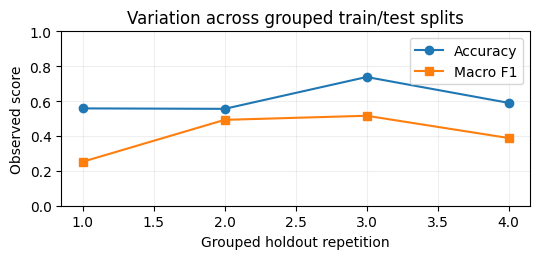

In [11]:
incorrect = holdout.loc[~holdout["matches_observed_code"]]
print("Holdout mismatches:", len(incorrect), "/", len(holdout))
print("Among unseen classes:", int((~holdout["matches_observed_code"] &
                                      ~holdout["class_seen_in_training"]).sum()))
display(incorrect[["ID", "observed_occupation", "model_prediction",
                   "class_seen_in_training"]].head(12))

# Diagnostic repeated grouped splits: a stability illustration, not a new tuned test.
stability=[]
for repeat, (a, b) in enumerate(GroupShuffleSplit(
        n_splits=4, test_size=0.22, random_state=21).split(X, y, groups=groups), 1):
    assert set(groups.iloc[a]).isdisjoint(groups.iloc[b])
    alternative = new_model().fit(X.iloc[a], y.iloc[a])
    forecast = alternative.predict(X.iloc[b])
    missing_class = ~y.iloc[b].isin(set(y.iloc[a]))
    stability.append({"split": repeat, "n_test": len(b),
                      "unseen_test_records": int(missing_class.sum()),
                      "accuracy": accuracy_score(y.iloc[b], forecast),
                      "macro_F1": f1_score(y.iloc[b], forecast, average="macro", zero_division=0)})
stability_df = pd.DataFrame(stability)
display(stability_df.round(3))
fig, ax = plt.subplots(figsize=(5.5, 2.7))
ax.plot(stability_df["split"], stability_df["accuracy"], marker="o", label="Accuracy")
ax.plot(stability_df["split"], stability_df["macro_F1"], marker="s", label="Macro F1")
ax.set(xlabel="Grouped holdout repetition", ylabel="Observed score", ylim=(0,1),
       title="Variation across grouped train/test splits")
ax.legend(loc="best")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 12. הצעות לסיווג חלקי: אדם בלולאה

לאחר הערכה בלבד, המודל מאומן מחדש על **כל 191 הסמלים המלאים** כדי להפיק הצעות לתשע הרשומות עם `X`. ההצעות אינן מדדי איכות ואינן משכתבות תוויות. השדה `uncalibrated_score` הוא ערך מודל בלתי מכויל, לא הסתברות אמינה לנכונות. כל הרשומות מופנות לבדיקת סמלן, משום שאין מערך כיול עצמאי ומייצג לקביעת סף אוטומציה.

In [12]:
review_model = new_model().fit(X, y)
partial_predictions = review_model.predict(model_matrix(partial))
partial_raw_score = review_model.predict_proba(model_matrix(partial)).max(axis=1)
review_queue = pd.DataFrame({
    "ID": partial["ID"].to_numpy(),
    "original_partial_code": partial["SemelMishlachSofi"].astype(str).to_numpy(),
    "proposed_code": partial_predictions,
    "uncalibrated_score": np.round(partial_raw_score, 3),
    "action": "manual_coder_review",
})
assert len(review_queue) == 9
assert all(review_queue["original_partial_code"].str.contains("X"))
display(review_queue)
print("Output tables: holdout (", len(holdout), ") and manual review (", len(review_queue), ")")

,ID,original_partial_code,proposed_code,uncalibrated_score,action
0,18,1XXX,2511,0.093,manual_coder_review
1,45,XXXX,2511,0.071,manual_coder_review
2,50,1XXX,2511,0.093,manual_coder_review
3,81,1XXX,2511,0.093,manual_coder_review
4,108,XXXX,2511,0.071,manual_coder_review
5,113,1XXX,2511,0.093,manual_coder_review
6,142,XXXX,5223,0.096,manual_coder_review
7,165,335X,3354,0.266,manual_coder_review
8,193,XXXX,5223,0.337,manual_coder_review


Output tables: holdout ( 42 ) and manual review ( 9 )


## 13. מסקנות, שיקולי פריסה ומקורות

**ממצאי מקור שאומתו:** 200 רשומות עם 18 עמודות; 18 הגדרות Metadata; שורת סיכום אחת שאינה משתתף; 9 תוויות מקצוע חלקיות; 9 חריגות בתנאי `MakorSachar`; 5 קודי ענף שאינם ארבעה תווים; קבוצת תיאורי עיסוק זהים המכילה סמלים סותרים. התוצאות הגרפיות מבוססות על כל 18 השדות, ולא רק על שדות המודל.

**גבולות פתרון המודל:** מדגם קטן, מספר מחלקות גדול ביחס לגודל המדגם, זיהוי חלקי בלבד של שידורי סקר חוזרים, רעש בתוויות, הסמלים X, היעדר הוכחה לגבי זמינות קוד הענף הסופי, והיעדר אמת מידה מקצועית מאומתת. אין לייחס למדדים המעבדתיים איכות תפעולית של למ״ס. אין לכייל הסתברויות, לבחור סף סיווג או למכן החלטה על מדגם סינתטי זה.

**צעדי הטמעה מומלצים, לפי סדר התלות:**

1. לחבר **מזהה נסקר יציב, גרסת שידור וחותמת זמן**, ולבנות מערך חלוקה נפרד לפי נסקר וזמן. בלי אלה לא ניתן להוכיח העדר זליגה בין גרסאות של אותו סקר.
2. ליצור **מדגם אמת מקצועי** עם הכרעת מחלוקות והפרדה בין רשומות סימול מלא ובין X. להשוות בין סמלנים, לבדוק כיסוי ותדירות מחלקות נדירות.
3. להגדיר חוזה נתונים ובדיקות תוכן: סוג, תחום כאשר קיים במטא-דאטה, תלות בין שדות, תוויות לא תקינות, חוסר שדות מקצועיים ועקיבות תיקונים.
4. לאמן ולהעריך על קבוצות בלתי תלויות לפי נסקר וזמן, למדוד איכות לפי תתי-קבוצות וכיסוי מחלקות, ולהגדיר רף שירות יחד עם סמלים מקצועיים.
5. להתחיל **במערכת המלצות לסמלנים** ולא באוטומציה מלאה. לכייל הסתברויות על נתונים נפרדים ורק לאחר מכן לשקול הימנעות/העברה לאדם. לנטר איכות תוויות, שינויי נתונים, חריגות, שיעורי הימנעות וגרסאות.

**תיעוד טכני רשמי:**

- [scikit-learn: common pitfalls / data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)
- [scikit-learn: ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
- [scikit-learn: TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)
- [scikit-learn: probability calibration](https://scikit-learn.org/stable/modules/calibration.html)

**הערת שחזור:** המחברת מבצעת SHA-256 של קובץ המקור ונכשלת בהודעה ברורה אם תוכן ה-Excel ב-GitHub משתנה. אין בה רשומות נתונים או רשימות קטגוריות שהוטמעו במקור הקוד.